<a href="https://colab.research.google.com/github/fralfaro/inf449-portafolio/blob/main/tareas/tarea-01/tarea_01.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Tarea 1: Demosaicking con filtro Bayer

**Objetivo de aprendizaje:** Identificar los filtros que componen un arreglo de filtros Bayer y resolver la tarea de interpolacion o *demosaicking* con algoritmos de interpolacion del estado del arte.

En esta tarea se implementara un sistema basico de fotografia computacional para reconstruir imagenes RGB a partir de una medicion en mosaico generada con un filtro Bayer.

## Enunciado

Implementar un sistema de fotografia computacional en Python para fotografia en color usando el filtro Bayer visto en clase para generar el mosaico o medicion.

A partir del mosaico Bayer, reconstruir la imagen RGB mediante demosaicking usando interpolacion 2D para estimar los valores faltantes de cada canal. En esta tarea se puede utilizar interpolacion bilineal para interpolar los canales rojo, verde y azul.

- Referencia filtro Bayer: <https://en.wikipedia.org/wiki/Bayer_filter>
- Dataset Kodak, 24 imagenes RGB: <https://github.com/MohamedBakrAli/Kodak-Lossless-True-Color-Image-Suite>
- Metricas de calidad:
  - PSNR: <https://www.mathworks.com/help/images/ref/psnr.html>
  - SSIM: <https://www.mathworks.com/help/images/ref/ssim.html>
  - SAM: <https://www.mathworks.com/help/images/ref/sam.html>

Se deben tabular las metricas de calidad para cada imagen y reportar el promedio y la desviacion estandar para todo el dataset.

> **Bonus:** implementar el algoritmo de demosaicking descrito en: <https://web.stanford.edu/class/ee367/reading/Demosaicing_ICASSP04.pdf>

## 1. Preparacion del entorno

Instalar o importar las librerias necesarias. Se recomienda usar `numpy`, `matplotlib`, `scipy`, `scikit-image`, `pandas` y `Pillow`.

In [18]:
# Imports
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from scipy.ndimage import uniform_filter, convolve, correlate


plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["image.cmap"] = "gray"


## 2. Carga del dataset Kodak

En Google Colab descargaremos el dataset directamente desde GitHub. El repositorio contiene las 24 imagenes RGB dentro de la carpeta `PhotoCD_PCD0992`.

La siguiente celda:

1. Clona el repositorio solo si no existe.
2. Define la ruta `DATASET_DIR`.
3. Busca las imagenes `.png`.
4. Verifica cuantas imagenes fueron encontradas.

> Referencia del dataset: <https://github.com/MohamedBakrAli/Kodak-Lossless-True-Color-Image-Suite/tree/master/PhotoCD_PCD0992>

In [19]:
# Descargar y cargar el dataset Kodak en Google Colab
from pathlib import Path

REPO_URL = "https://github.com/MohamedBakrAli/Kodak-Lossless-True-Color-Image-Suite.git"
REPO_DIR = Path("Kodak-Lossless-True-Color-Image-Suite")

# En Colab, clonar el repositorio si todavia no existe.
# Si ejecutas la celda mas de una vez, no se vuelve a descargar.
if not REPO_DIR.exists():
    !git clone {REPO_URL}

# Carpeta que contiene las 24 imagenes Kodak.
DATASET_DIR = REPO_DIR / "PhotoCD_PCD0992"

# Buscar imagenes PNG del dataset.
image_paths = sorted(DATASET_DIR.glob("*.png"))

print(f"Ruta del dataset: {DATASET_DIR}")
print(f"Imagenes encontradas: {len(image_paths)}")

for path in image_paths:
    print(path.name)

assert len(image_paths) == 24, "No se encontraron las 24 imagenes Kodak. Revisa la descarga o la ruta DATASET_DIR."

Ruta del dataset: Kodak-Lossless-True-Color-Image-Suite/PhotoCD_PCD0992
Imagenes encontradas: 24
01.png
02.png
03.png
04.png
05.png
06.png
07.png
08.png
09.png
10.png
11.png
12.png
13.png
14.png
15.png
16.png
17.png
18.png
19.png
20.png
21.png
22.png
23.png
24.png


Imagen seleccionada: 01.png
Dimensiones: (512, 768, 3)
Valor minimo: 0.0000
Valor maximo: 1.0000
Tipo de dato: float64


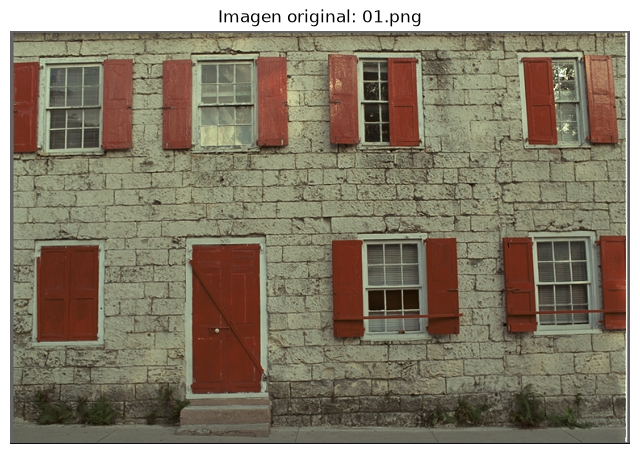

In [20]:
def load_rgb_image(path):
    """Carga una imagen RGB y la normaliza al rango [0, 1]."""
    image = Image.open(path).convert("RGB")
    return np.asarray(image, dtype=np.float64) / 255.0


# Cargar una imagen de prueba para inspeccion visual
if image_paths:
    index = 0  # Cambiar entre 0 y 23 para visualizar otra imagen

    sample_path = image_paths[index]
    sample = load_rgb_image(sample_path)

    print(f"Imagen seleccionada: {sample_path.name}")
    print(f"Dimensiones: {sample.shape}")
    print(f"Valor minimo: {sample.min():.4f}")
    print(f"Valor maximo: {sample.max():.4f}")
    print(f"Tipo de dato: {sample.dtype}")

    plt.figure(figsize=(8, 6))
    plt.imshow(sample)
    plt.title(f"Imagen original: {sample_path.name}")
    plt.axis("off")
    plt.show()

## 3. Generacion del mosaico Bayer

Una imagen RGB original puede representarse como un tensor $I \in \mathbb{R}^{M \times N \times C}$, con $C=3$ canales: rojo, verde y azul.

Para el patron Bayer **RGGB**, se define primero un bloque base $B \in \{0,1\}^{2 \times 2 \times 3}$:

$$
B_0 =
\begin{bmatrix}
1 & 0 \\
0 & 0
\end{bmatrix},
\quad
B_1 =
\begin{bmatrix}
0 & 1 \\
1 & 0
\end{bmatrix},
\quad
B_2 =
\begin{bmatrix}
0 & 0 \\
0 & 1
\end{bmatrix}
$$

donde $B_0$, $B_1$ y $B_2$ corresponden a las posiciones medidas de los canales rojo, verde y azul, respectivamente.

Luego se replica este bloque sobre toda la imagen usando producto de Kronecker:

$$
T_c = \mathbf{1}_{M/2 \times N/2} \otimes B_c, \quad c \in \{0,1,2\}
$$

Finalmente, el mosaico Bayer medido se obtiene como:

$$
Y = \sum_{c=0}^{C-1} T_c \odot I_c
$$

Asi, $Y$ es una imagen 2D con una sola medicion de color por pixel, mientras que $T$ indica que canal fue observado en cada posicion.


512 768


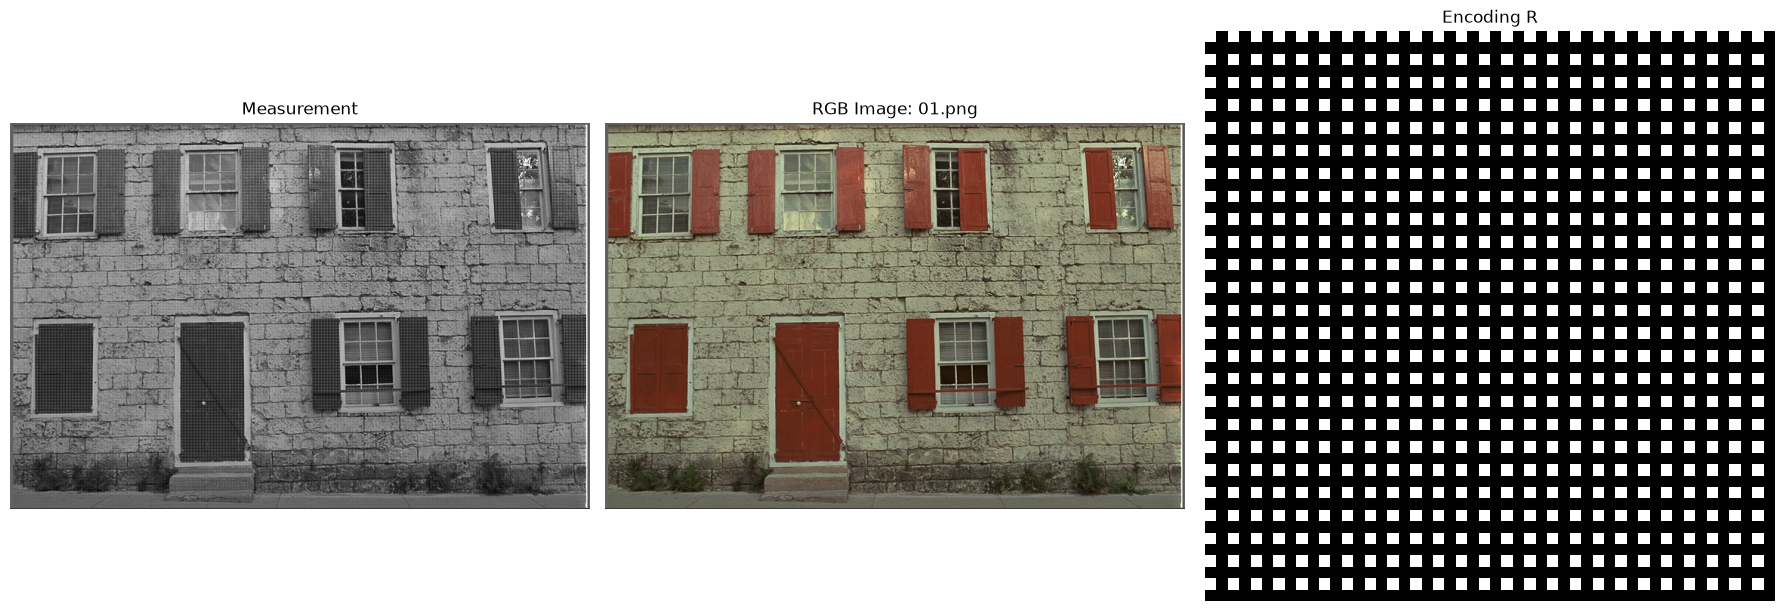

In [21]:
def bayer_filter_definition():
    """Define el filtro Bayer RGGB como tensor B de tamano 2 x 2 x 3."""
    C = 3
    B = np.zeros((2, 2, C))

    # Bayer Filter definition, canales: 0=R, 1=G, 2=B
    B[0, 0, 0] = 1
    B[1, 1, 2] = 1
    B[0, 1, 1] = 1
    B[1, 0, 1] = 1

    return B


def bayer_tensor(shape, pattern="RGGB"):
    """Construye el tensor T del filtro Bayer usando producto de Kronecker."""
    if pattern != "RGGB":
        raise NotImplementedError("Por ahora solo se implementa el patron RGGB.")

    M, N = shape[:2]
    C = 3
    B = bayer_filter_definition()

    if M % 2 != 0 or N % 2 != 0:
        raise ValueError("La imagen debe tener dimensiones pares para construir T con bloques 2x2.")

    I = np.ones((M // 2, N // 2))
    T = np.zeros((M, N, C))

    for c in range(C):
        T[:, :, c] = np.kron(I, B[:, :, c])

    return T


def bayer_masks(shape, pattern="RGGB"):
    """Retorna mascaras booleanas R, G y B a partir del tensor Bayer T."""
    T = bayer_tensor(shape, pattern=pattern)
    return T[:, :, 0].astype(bool), T[:, :, 1].astype(bool), T[:, :, 2].astype(bool)


def rgb_to_bayer_mosaic(image_rgb, pattern="RGGB"):
    """Genera el mosaico Bayer Y = sum_c T_c * I_c desde una imagen RGB."""
    T = bayer_tensor(image_rgb.shape, pattern=pattern)
    Y = np.zeros(image_rgb.shape[:2], dtype=image_rgb.dtype)

    for c in range(T.shape[-1]):
        Y = Y + T[:, :, c] * image_rgb[:, :, c]

    return Y


# Visualizar imagen original, mosaico Bayer y una mascara de codificacion
if image_paths:
    index = 0

    sample = load_rgb_image(image_paths[index])
    M, N, L = np.shape(sample)
    print(M, N)

    T = bayer_tensor(sample.shape)
    Y = rgb_to_bayer_mosaic(sample)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(Y[:, :], cmap="gray")
    axes[0].set_title("Measurement")
    axes[0].axis("off")

    axes[1].imshow(sample, vmin=0, vmax=1)
    axes[1].set_title(f"RGB Image: {image_paths[index].name}")
    axes[1].axis("off")

    axes[2].imshow(T[0:50, 0:50, 0], vmin=0, vmax=1)
    axes[2].set_title("Encoding R")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()


## 4. Demosaicking por interpolacion 2D

El mosaico Bayer contiene solo una medicion de color por pixel. Por lo tanto, para reconstruir una imagen RGB completa es necesario estimar los dos canales faltantes en cada posicion de la imagen. Este proceso se conoce como **demosaicking**.

Primero se separan las muestras observadas por canal usando el tensor Bayer $T$:

$$
\bar{I}_c = T_c \odot Y
$$

Luego, cada canal incompleto se interpola mediante un filtro 2D. En esta implementacion se usa demosaicking bilineal por convolucion/correlacion, con filtros distintos para los canales rojo/azul y verde:

$$
H_{R,B} =
\begin{bmatrix}
1 & 2 & 1 \\
2 & 4 & 2 \\
1 & 2 & 1
\end{bmatrix},
\quad
H_G =
\begin{bmatrix}
0 & 1 & 0 \\
1 & 4 & 1 \\
0 & 1 & 0
\end{bmatrix}
$$

La reconstruccion de cada canal se calcula como:

$$
\hat{I}_c = \frac{1}{4}(\bar{I}_c * H_c)
$$

Finalmente, los tres canales reconstruidos se apilan para formar la imagen RGB estimada $\hat{I}$.


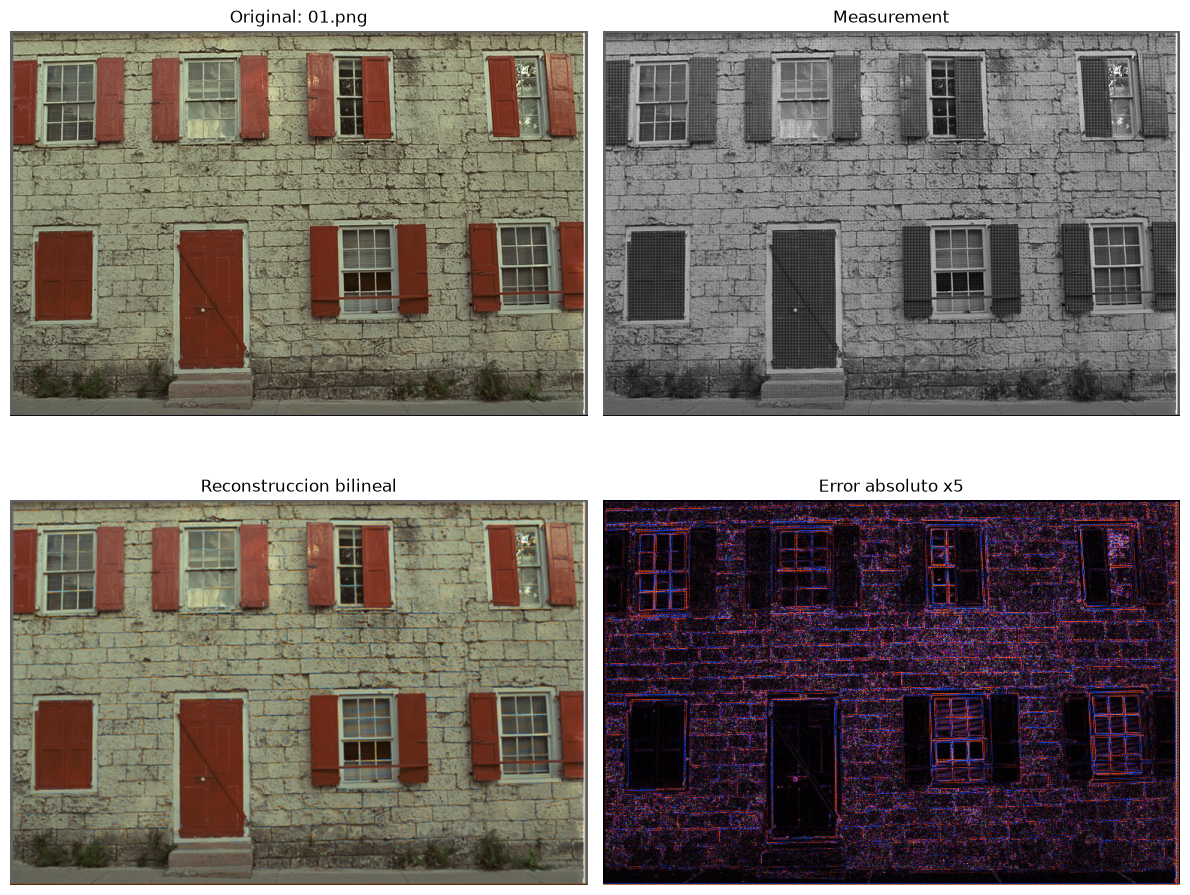

In [22]:
def demosaick_interpolation(mosaic, pattern="RGGB", method="bilinear"):
    """Reconstruye una imagen RGB desde un mosaico Bayer usando interpolacion 2D bilineal."""
    if method != "bilinear":
        raise NotImplementedError("Esta implementacion usa demosaicking bilineal por filtros 2D.")

    M, N = mosaic.shape
    C = 3
    T = bayer_tensor(mosaic.shape, pattern=pattern)

    It = np.zeros((M, N, C), float)
    Ir = np.zeros((M, N, C), float)

    kernel = np.zeros((3, 3, C))
    kernel[:, :, 0] = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]])
    kernel[:, :, 1] = np.array([[0, 1, 0], [1, 4, 1], [0, 1, 0]])
    kernel[:, :, 2] = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]])

    # Bilinear Demosaicking
    for c in range(C):
        It[:, :, c] = T[:, :, c] * mosaic
        Ir[:, :, c] = correlate(It[:, :, c], kernel[:, :, c], mode="mirror") / 4

    return np.clip(Ir, 0.0, 1.0)


# Probar reconstruccion en una imagen del dataset
if image_paths:
    index = 0

    sample = load_rgb_image(image_paths[index])
    Y = rgb_to_bayer_mosaic(sample)
    reconstructed = demosaick_interpolation(Y, method="bilinear")
    error = np.abs(sample - reconstructed)

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    axes[0, 0].imshow(sample)
    axes[0, 0].set_title(f"Original: {image_paths[index].name}")
    axes[0, 0].axis("off")

    axes[0, 1].imshow(Y, cmap="gray")
    axes[0, 1].set_title("Measurement")
    axes[0, 1].axis("off")

    axes[1, 0].imshow(reconstructed, vmin=0, vmax=1)
    axes[1, 0].set_title("Reconstruccion bilineal")
    axes[1, 0].axis("off")

    axes[1, 1].imshow(np.clip(error * 5, 0, 1))
    axes[1, 1].set_title("Error absoluto x5")
    axes[1, 1].axis("off")

    plt.tight_layout()
    plt.show()


## 5. Metricas de calidad

Para evaluar la calidad de la reconstruccion se compara la imagen RGB original $I$ con la imagen reconstruida $\hat{I}$. La comparacion se realiza usando tres metricas: **PSNR**, **SSIM** y **SAM**.

Estas metricas permiten analizar distintos aspectos del error de reconstruccion:

- **PSNR** mide el error cuadratico entre ambas imagenes.
- **SSIM** mide la similitud estructural percibida.
- **SAM** mide la diferencia angular entre los vectores de color RGB.

### PSNR

El **Peak Signal-to-Noise Ratio** compara la energia maxima posible de la imagen con el error cuadratico medio entre la imagen original y la reconstruida.

Primero se calcula el error cuadratico medio:

$$
MSE = \frac{1}{HWC}\sum_{i=1}^{H}\sum_{j=1}^{W}\sum_{c=1}^{C}
\left(I(i,j,c)-\hat{I}(i,j,c)\right)^2
$$

Luego, el PSNR se define como:

$$
PSNR = 10 \log_{10}\left(\frac{MAX_I^2}{MSE}\right)
$$

donde $MAX_I$ es el valor maximo posible de la imagen. Como las imagenes se normalizan al rango $[0,1]$, en este caso $MAX_I=1$.

Un valor mayor de PSNR indica una reconstruccion con menor error numerico.

### SSIM

El **Structural Similarity Index** mide la similitud estructural entre dos imagenes. A diferencia del PSNR, no solo considera el error pixel a pixel, sino tambien cambios en luminancia, contraste y estructura.

De forma general, SSIM compara dos imagenes $x$ e $y$ mediante:

$$
SSIM(x,y) =
\frac{(2\mu_x\mu_y + C_1)(2\sigma_{xy}+C_2)}
{(\mu_x^2+\mu_y^2+C_1)(\sigma_x^2+\sigma_y^2+C_2)}
$$

donde:

- $\mu_x$ y $\mu_y$ son los promedios locales.
- $\sigma_x^2$ y $\sigma_y^2$ son las varianzas locales.
- $\sigma_{xy}$ es la covarianza local.
- $C_1$ y $C_2$ son constantes de estabilizacion.

El valor de SSIM suele estar entre 0 y 1. Un valor cercano a 1 indica mayor similitud estructural con la imagen original.

### SAM

El **Spectral Angle Mapper** mide el angulo entre el vector RGB original y el vector RGB reconstruido en cada pixel.

Para un pixel en la posicion $(i,j)$, se consideran los vectores:

$$
\mathbf{v}(i,j) =
\begin{bmatrix}
R(i,j) \\
G(i,j) \\
B(i,j)
\end{bmatrix}
$$

y

$$
\hat{\mathbf{v}}(i,j) =
\begin{bmatrix}
\hat{R}(i,j) \\
\hat{G}(i,j) \\
\hat{B}(i,j)
\end{bmatrix}
$$

El angulo espectral se calcula como:

$$
SAM(i,j) =
\arccos
\left(
\frac{
\mathbf{v}(i,j) \cdot \hat{\mathbf{v}}(i,j)
}{
\|\mathbf{v}(i,j)\|_2 \|\hat{\mathbf{v}}(i,j)\|_2
}
\right)
$$

Finalmente, se reporta el promedio del angulo sobre todos los pixeles de la imagen:

$$
SAM =
\frac{1}{HW}
\sum_{i=1}^{H}
\sum_{j=1}^{W}
SAM(i,j)
$$

En esta tarea se reporta SAM en grados. Un valor menor de SAM indica que el color reconstruido tiene una direccion mas parecida al color original en el espacio RGB.


In [23]:
def compute_psnr(reference, estimate, data_range=1.0):
    """Calcula PSNR entre una imagen de referencia y una imagen estimada."""
    mse = np.mean((reference - estimate) ** 2)

    if mse == 0:
        return np.inf

    return 10 * np.log10((data_range ** 2) / mse)


def compute_ssim(reference, estimate, data_range=1.0, window_size=7):
    """
    Calcula SSIM promedio para una imagen RGB.

    Esta implementacion calcula SSIM canal por canal usando estadisticas locales
    con una ventana cuadrada y luego promedia los tres canales.
    """

    reference = reference.astype(np.float64)
    estimate = estimate.astype(np.float64)

    C1 = (0.01 * data_range) ** 2
    C2 = (0.03 * data_range) ** 2

    ssim_channels = []

    for c in range(reference.shape[-1]):
        x = reference[..., c]
        y = estimate[..., c]

        mu_x = uniform_filter(x, size=window_size)
        mu_y = uniform_filter(y, size=window_size)

        mu_x_sq = mu_x ** 2
        mu_y_sq = mu_y ** 2
        mu_xy = mu_x * mu_y

        sigma_x_sq = uniform_filter(x * x, size=window_size) - mu_x_sq
        sigma_y_sq = uniform_filter(y * y, size=window_size) - mu_y_sq
        sigma_xy = uniform_filter(x * y, size=window_size) - mu_xy

        numerator = (2 * mu_xy + C1) * (2 * sigma_xy + C2)
        denominator = (mu_x_sq + mu_y_sq + C1) * (sigma_x_sq + sigma_y_sq + C2)

        ssim_map = numerator / denominator
        ssim_channels.append(np.mean(ssim_map))

    return float(np.mean(ssim_channels))


def compute_sam(reference, estimate, eps=1e-12):
    """Calcula SAM promedio en grados entre dos imagenes RGB."""
    ref = reference.reshape(-1, reference.shape[-1])
    est = estimate.reshape(-1, estimate.shape[-1])

    dot = np.sum(ref * est, axis=1)
    ref_norm = np.linalg.norm(ref, axis=1)
    est_norm = np.linalg.norm(est, axis=1)

    cosine = dot / (ref_norm * est_norm + eps)
    cosine = np.clip(cosine, -1.0, 1.0)

    angles = np.arccos(cosine)

    return np.degrees(np.mean(angles))


def compute_metrics(reference, estimate):
    """Calcula PSNR, SSIM y SAM para una imagen reconstruida."""
    reference = np.clip(reference, 0.0, 1.0)
    estimate = np.clip(estimate, 0.0, 1.0)

    psnr = compute_psnr(reference, estimate, data_range=1.0)
    ssim = compute_ssim(reference, estimate, data_range=1.0)
    sam = compute_sam(reference, estimate)

    return {
        "PSNR": psnr,
        "SSIM": ssim,
        "SAM": sam,
    }

# Calcular metricas para una imagen de prueba
if image_paths:
    index = 0

    sample = load_rgb_image(image_paths[index])
    mosaic = rgb_to_bayer_mosaic(sample)
    reconstructed = demosaick_interpolation(mosaic, method="bilinear")

    metrics = compute_metrics(sample, reconstructed)

    metrics_df = pd.DataFrame([{
        "imagen": image_paths[index].name,
        "metodo": "bilinear",
        "PSNR [dB]": metrics["PSNR"],
        "SSIM": metrics["SSIM"],
        "SAM [grados]": metrics["SAM"],
    }]).round(4)

    display(metrics_df)

,imagen,metodo,PSNR [dB],SSIM,SAM [grados]
0,01.png,bilinear,26.0131,0.8166,3.6231


## 6. Evaluacion completa del dataset

En esta seccion se ejecuta el flujo completo para las 24 imagenes Kodak:

1. Cargar la imagen RGB original.
2. Generar el mosaico Bayer con patron `RGGB`.
3. Reconstruir la imagen mediante demosaicking por interpolacion bilineal.
4. Calcular las metricas PSNR, SSIM y SAM.
5. Guardar los resultados en una tabla por imagen.
6. Calcular el promedio y la desviacion estandar para todo el dataset.


In [24]:
from tqdm.notebook import tqdm


def evaluate_dataset(image_paths, method="bilinear", pattern="RGGB"):
    """Evalua el proceso completo de demosaicking para todas las imagenes."""
    rows = []

    for index, path in enumerate(tqdm(image_paths, desc="Evaluando imagenes Kodak")):
        original = load_rgb_image(path)
        mosaic = rgb_to_bayer_mosaic(original, pattern=pattern)
        reconstructed = demosaick_interpolation(mosaic, pattern=pattern, method=method)
        metrics = compute_metrics(original, reconstructed)

        rows.append({
            "indice": index,
            "imagen": path.name,
            "patron_bayer": pattern,
            "metodo": method,
            "PSNR [dB]": metrics["PSNR"],
            "SSIM": metrics["SSIM"],
            "SAM [grados]": metrics["SAM"],
        })

    return pd.DataFrame(rows)


# Evaluar las 24 imagenes Kodak
results = evaluate_dataset(
    image_paths=image_paths,
    method="bilinear",
    pattern="RGGB",
)

# Tabla de metricas por imagen, redondeada para presentacion
results_rounded = results.copy()
results_rounded["PSNR [dB]"] = results_rounded["PSNR [dB]"].round(4)
results_rounded["SSIM"] = results_rounded["SSIM"].round(4)
results_rounded["SAM [grados]"] = results_rounded["SAM [grados]"].round(4)

display(results_rounded)


Evaluando imagenes Kodak:   0%|          | 0/24 [00:00<?, ?it/s]

,indice,imagen,patron_bayer,metodo,PSNR [dB],SSIM,SAM [grados]
0,0,01.png,RGGB,bilinear,26.0131,0.8166,3.6231
1,1,02.png,RGGB,bilinear,32.0180,0.8984,1.6612
2,2,03.png,RGGB,bilinear,32.8477,0.9309,1.2783
3,3,04.png,RGGB,bilinear,32.5195,0.9157,1.5814
4,4,05.png,RGGB,bilinear,26.4544,0.8858,4.1863
5,5,06.png,RGGB,bilinear,27.3858,0.8516,2.6478
6,6,07.png,RGGB,bilinear,32.3303,0.9536,1.6316
7,7,08.png,RGGB,bilinear,23.5948,0.8359,4.1950
8,8,09.png,RGGB,bilinear,31.6912,0.9216,1.4048
9,9,10.png,RGGB,bilinear,31.6152,0.9218,1.4285


In [25]:
# Promedio y desviacion estandar para todo el dataset
summary = results[["PSNR [dB]", "SSIM", "SAM [grados]"]].agg(["mean", "std"])
summary_rounded = summary.round(4)

display(summary_rounded)

# Guardar resultados en archivos CSV
output_dir = Path("resultados")
output_dir.mkdir(exist_ok=True)

results_rounded.to_csv(output_dir / "metricas_por_imagen.csv", index=False)
summary_rounded.to_csv(output_dir / "metricas_resumen.csv")

print(f"Resultados guardados en: {output_dir}")


,PSNR [dB],SSIM,SAM [grados]
mean,29.4849,0.8917,2.4072
std,2.8141,0.0399,1.0290


Resultados guardados en: resultados


## 7. Visualizacion de resultados

Para inspeccionar cualitativamente el resultado, se muestra una imagen del dataset en una grilla 2 x 2:

- Imagen RGB original.
- Mosaico Bayer `RGGB`.
- Imagen reconstruida con interpolacion bilineal.
- Mapa de error absoluto amplificado para facilitar la visualizacion.


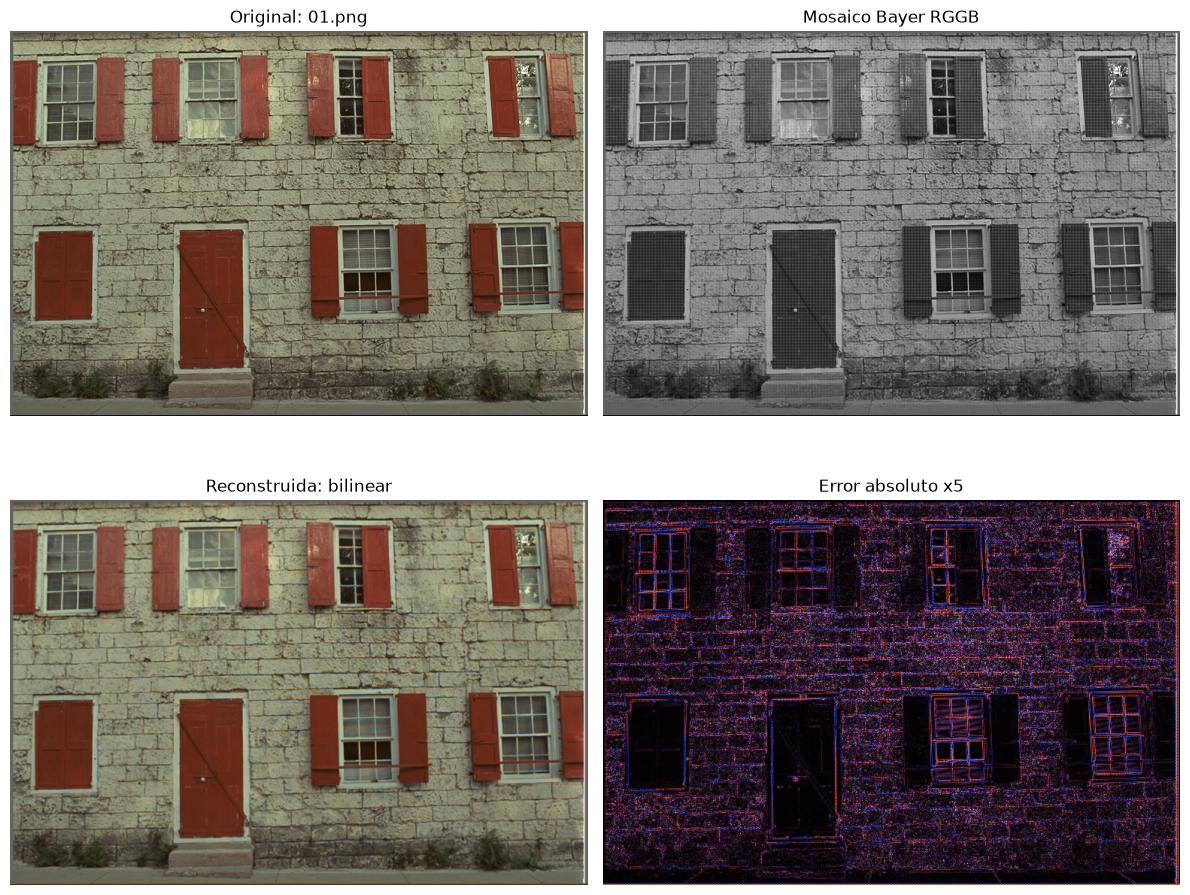

,imagen,metodo,PSNR [dB],SSIM,SAM [grados]
0,01.png,bilinear,26.0131,0.8166,3.6231


In [26]:
def visualize_reconstruction(path, method="bilinear", pattern="RGGB", error_scale=5):
    """Muestra original, mosaico Bayer, reconstruccion y error absoluto en una grilla 2x2."""
    original = load_rgb_image(path)
    mosaic = rgb_to_bayer_mosaic(original, pattern=pattern)
    reconstructed = demosaick_interpolation(mosaic, pattern=pattern, method=method)
    error = np.abs(original - reconstructed)
    metrics = compute_metrics(original, reconstructed)

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    axes[0, 0].imshow(original)
    axes[0, 0].set_title(f"Original: {path.name}")
    axes[0, 0].axis("off")

    axes[0, 1].imshow(mosaic, cmap="gray")
    axes[0, 1].set_title(f"Mosaico Bayer {pattern}")
    axes[0, 1].axis("off")

    axes[1, 0].imshow(reconstructed)
    axes[1, 0].set_title(f"Reconstruida: {method}")
    axes[1, 0].axis("off")

    axes[1, 1].imshow(np.clip(error * error_scale, 0, 1))
    axes[1, 1].set_title(f"Error absoluto x{error_scale}")
    axes[1, 1].axis("off")

    plt.tight_layout()
    plt.show()

    metrics_df = pd.DataFrame([{
        "imagen": path.name,
        "metodo": method,
        "PSNR [dB]": metrics["PSNR"],
        "SSIM": metrics["SSIM"],
        "SAM [grados]": metrics["SAM"],
    }]).round(4)

    display(metrics_df)
    return metrics


# Cambiar este indice para visualizar otras imagenes del dataset: 0 a 23
if image_paths:
    index = 0
    visualize_reconstruction(image_paths[index], method="bilinear", pattern="RGGB")


**Conclusiones**:

En esta primera parte se implemento el flujo basico de un sistema de fotografia computacional en color: a partir de una imagen RGB del dataset Kodak se construyo el mosaico Bayer con patron `RGGB`, usando el tensor de codificacion `T`, y luego se reconstruyo una imagen RGB mediante demosaicking bilineal por filtros 2D. Este procedimiento permite recuperar los tres canales de color desde una unica medicion por pixel, siguiendo directamente el modelo de medicion descrito en el enunciado.

Para el dataset Kodak completo, la reconstruccion bilineal obtuvo un PSNR promedio de **29.4849 dB**, un SSIM promedio de **0.8917** y un SAM promedio de **2.4072 grados**. Estos resultados muestran que el metodo logra una reconstruccion razonable: el nivel de error numerico es moderado, la estructura visual general se conserva bastante bien y la direccion de los vectores RGB reconstruidos se mantiene cercana a la imagen original.

Sin embargo, al observar las imagenes reconstruidas se aprecian artefactos visuales propios de metodos simples de demosaicking. En particular, en algunas zonas aparecen franjas de colores tipo arcoiris o falso color, especialmente cerca de bordes, texturas finas y regiones con cambios abruptos de intensidad. Este efecto ocurre porque la interpolacion bilineal reconstruye cada canal usando filtros fijos y locales, sin considerar de manera adaptativa la direccion de los bordes ni la correlacion entre los canales RGB.

Por lo tanto, aunque el demosaicking bilineal cumple correctamente como metodo base y permite resolver la tarea principal, sus limitaciones son visibles en escenas con mayor detalle espacial. Esto motiva el uso de algoritmos mas avanzados, como el metodo de Malvar, He y Cutler (2004), que incorporan correcciones de gradiente para reducir artefactos de falso color y mejorar la calidad de reconstruccion.


## Bonus: algoritmo ICASSP 2004

Implementar y evaluar el algoritmo descrito en el articulo:

<https://web.stanford.edu/class/ee367/reading/Demosaicing_ICASSP04.pdf>

En esta seccion se debe explicar brevemente la idea principal del metodo, implementar la reconstruccion y compararla contra la interpolacion bilineal usando las mismas metricas.

In [27]:
def demosaick_malvar2004(mosaic, pattern="RGGB"):
    """
    Demosaicking Malvar, He y Cutler (2004).

    Paper:
    High-Quality Linear Interpolation for Demosaicing of
    Bayer-Patterned Color Images.

    Esta implementacion usa filtros lineales 5x5 para reconstruir
    los canales RGB desde un mosaico Bayer.
    """
    if pattern != "RGGB":
        raise NotImplementedError("Esta version implementa solo el patron RGGB.")

    mosaic = mosaic.astype(np.float64)

    mask_r, mask_g, mask_b = bayer_masks(mosaic.shape, pattern=pattern)

    # Filtro para estimar G en posiciones R o B
    kernel_g_at_rb = np.array([
        [0,  0, -1,  0,  0],
        [0,  0,  2,  0,  0],
        [-1, 2,  4,  2, -1],
        [0,  0,  2,  0,  0],
        [0,  0, -1,  0,  0],
    ], dtype=np.float64) / 8

    # Filtro para estimar R en G de fila R / B en G de fila B
    kernel_rb_at_g_1 = np.array([
        [0,   0, 0.5, 0,   0],
        [0,  -1, 0,  -1,   0],
        [-1,  4, 5,   4,  -1],
        [0,  -1, 0,  -1,   0],
        [0,   0, 0.5, 0,   0],
    ], dtype=np.float64) / 8

    # Filtro transpuesto para la otra orientacion
    kernel_rb_at_g_2 = kernel_rb_at_g_1.T

    # Filtro para estimar R en B y B en R
    kernel_rb_at_br = np.array([
        [0,    0, -1.5, 0,    0],
        [0,    2,  0,   2,    0],
        [-1.5, 0,  6,   0,   -1.5],
        [0,    2,  0,   2,    0],
        [0,    0, -1.5, 0,    0],
    ], dtype=np.float64) / 8

    # Inicializar canales con los valores conocidos
    red = mosaic * mask_r
    green = mosaic * mask_g
    blue = mosaic * mask_b

    # Reconstruir G en posiciones R y B
    green_interp = convolve(mosaic, kernel_g_at_rb, mode="mirror")
    green = np.where(mask_r | mask_b, green_interp, green)

    # Convoluciones para R y B faltantes
    rb_interp_1 = convolve(mosaic, kernel_rb_at_g_1, mode="mirror")
    rb_interp_2 = convolve(mosaic, kernel_rb_at_g_2, mode="mirror")
    rb_interp_3 = convolve(mosaic, kernel_rb_at_br, mode="mirror")

    height, width = mosaic.shape
    rows, cols = np.indices((height, width))

    red_row = rows % 2 == 0
    blue_row = rows % 2 == 1
    red_col = cols % 2 == 0
    blue_col = cols % 2 == 1

    # Para patron RGGB:
    # R esta en fila par, columna par.
    # B esta en fila impar, columna impar.

    # R en pixeles verdes
    red = np.where(red_row & blue_col, rb_interp_1, red)
    red = np.where(blue_row & red_col, rb_interp_2, red)

    # B en pixeles verdes
    blue = np.where(blue_row & red_col, rb_interp_1, blue)
    blue = np.where(red_row & blue_col, rb_interp_2, blue)

    # R en pixeles azules y B en pixeles rojos
    red = np.where(mask_b, rb_interp_3, red)
    blue = np.where(mask_r, rb_interp_3, blue)

    reconstructed = np.stack([red, green, blue], axis=-1)

    return np.clip(reconstructed, 0.0, 1.0)

In [28]:
def evaluate_dataset_malvar(image_paths, pattern="RGGB"):
    rows = []

    for index, path in enumerate(tqdm(image_paths, desc="Evaluando Malvar 2004")):
        original = load_rgb_image(path)
        mosaic = rgb_to_bayer_mosaic(original, pattern=pattern)
        reconstructed = demosaick_malvar2004(mosaic, pattern=pattern)
        metrics = compute_metrics(original, reconstructed)

        rows.append({
            "indice": index,
            "imagen": path.name,
            "patron_bayer": pattern,
            "metodo": "Malvar2004",
            "PSNR [dB]": metrics["PSNR"],
            "SSIM": metrics["SSIM"],
            "SAM [grados]": metrics["SAM"],
        })

    return pd.DataFrame(rows)


malvar_results = evaluate_dataset_malvar(image_paths)

malvar_results_rounded = malvar_results.copy()
malvar_results_rounded["PSNR [dB]"] = malvar_results_rounded["PSNR [dB]"].round(4)
malvar_results_rounded["SSIM"] = malvar_results_rounded["SSIM"].round(4)
malvar_results_rounded["SAM [grados]"] = malvar_results_rounded["SAM [grados]"].round(4)

display(malvar_results_rounded)

Evaluando Malvar 2004:   0%|          | 0/24 [00:00<?, ?it/s]

,indice,imagen,patron_bayer,metodo,PSNR [dB],SSIM,SAM [grados]
0,0,01.png,RGGB,Malvar2004,31.6608,0.9553,2.4269
1,1,02.png,RGGB,Malvar2004,35.8906,0.9617,1.2856
2,2,03.png,RGGB,Malvar2004,37.1981,0.9764,0.9568
3,3,04.png,RGGB,Malvar2004,37.4597,0.9738,1.1332
4,4,05.png,RGGB,Malvar2004,32.8102,0.9746,2.9792
5,5,06.png,RGGB,Malvar2004,32.5555,0.9597,1.8109
6,6,07.png,RGGB,Malvar2004,37.6348,0.9835,1.1268
7,7,08.png,RGGB,Malvar2004,29.1082,0.9560,2.9363
8,8,09.png,RGGB,Malvar2004,37.2758,0.9731,1.0336
9,9,10.png,RGGB,Malvar2004,37.7716,0.9754,1.0147


In [29]:
comparison = pd.concat([results, malvar_results], ignore_index=True)

comparison_summary = comparison.groupby("metodo")[[
    "PSNR [dB]",
    "SSIM",
    "SAM [grados]"
]].agg(["mean", "std"]).round(4)

display(comparison_summary)

PSNR [dB]            SSIM         SAM [grados]        
                mean     std    mean     std         mean     std
metodo                                                           
Malvar2004   34.6940  2.5837  0.9681  0.0082       1.7049  0.6901
bilinear     29.4849  2.8141  0.8917  0.0399       2.4072  1.0290

In [31]:
psnr_gain = (
    comparison_summary.loc["Malvar2004", ("PSNR [dB]", "mean")]
    - comparison_summary.loc["bilinear", ("PSNR [dB]", "mean")]
)

ssim_gain = (
    comparison_summary.loc["Malvar2004", ("SSIM", "mean")]
    - comparison_summary.loc["bilinear", ("SSIM", "mean")]
)

sam_reduction = (
    comparison_summary.loc["bilinear", ("SAM [grados]", "mean")]
    - comparison_summary.loc["Malvar2004", ("SAM [grados]", "mean")]
)

print(f"Mejora PSNR: {psnr_gain:.4f} dB")
print(f"Mejora SSIM: {ssim_gain:.4f}")
print(f"Reduccion SAM: {sam_reduction:.4f} grados")

Mejora PSNR: 5.2091 dB
Mejora SSIM: 0.0764
Reduccion SAM: 0.7023 grados


**Conclusiones**:

Al incorporar el algoritmo de Malvar, He y Cutler (2004), se observa una mejora clara respecto del demosaicking bilineal. Este metodo utiliza filtros lineales de mayor tamano y terminos de correccion que aprovechan mejor la informacion local de la imagen, por lo que no se limita a promediar muestras vecinas de forma uniforme.

La comparacion cuantitativa confirma esta mejora. El PSNR promedio aumenta de **29.4849 dB** con el metodo bilineal a **34.6940 dB** con Malvar2004, lo que corresponde a una ganancia aproximada de **5.2091 dB**. El SSIM promedio tambien mejora, pasando de **0.8917** a **0.9681**, lo que indica que la estructura visual de las imagenes se conserva con mayor fidelidad. Ademas, el SAM promedio disminuye de **2.4072 grados** a **1.7049 grados**, mostrando una mejor preservacion de la relacion espectral entre los canales RGB.

Desde el punto de vista visual, Malvar2004 reduce los artefactos que se observaban en la reconstruccion bilineal. Las franjas tipo arcoiris, el falso color y los errores en bordes se vuelven menos notorios, especialmente en zonas con textura o detalles finos. Esto se debe a que el algoritmo incorpora informacion de gradientes y aprovecha mejor la correlacion entre canales, produciendo una reconstruccion mas estable y natural.

En conclusion, el metodo bilineal permite entender e implementar el proceso completo de captura Bayer y demosaicking, pero presenta limitaciones visibles en calidad visual. El algoritmo de Malvar2004 entrega mejores resultados tanto en las metricas objetivas como en la inspeccion cualitativa, por lo que representa una alternativa mas adecuada cuando se busca reducir artefactos y mejorar la fidelidad de la imagen reconstruida.
